In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Basic overview
print("Shape:", df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Convert TotalCharges to numeric (it's stored as string due to blank spaces)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many missing values this created
print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())

# Check missing values across all columns
print("\nMissing values per column:")
print(df.isnull().sum())

Missing values in TotalCharges: 11

Missing values per column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [4]:
# Check the rows with missing TotalCharges
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [5]:
# Drop rows with missing TotalCharges (new customers with tenure = 0)
df = df.dropna(subset=['TotalCharges'])

# Confirm
print("New shape:", df.shape)
print("Missing values now:", df['TotalCharges'].isnull().sum())

New shape: (7032, 21)
Missing values now: 0


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21744\619958415.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette=['#2ecc71', '#e74c3c'])


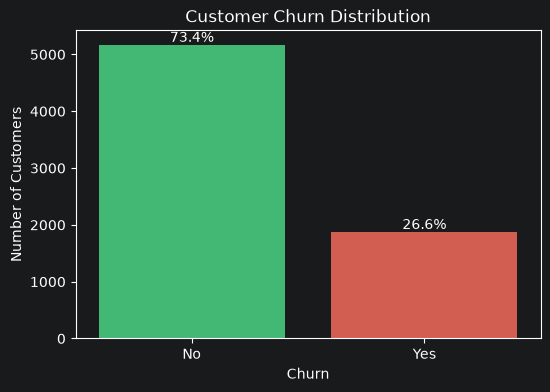

In [6]:
# Visualize churn distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

# Add percentage labels
total = len(df)
for p in plt.gca().patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    plt.gca().annotate(percentage, (p.get_x() + p.get_width()/2, p.get_height()),
                        ha='center', va='bottom')

plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21744\994917206.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0], palette=['#2ecc71', '#e74c3c'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21744\994917206.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'])


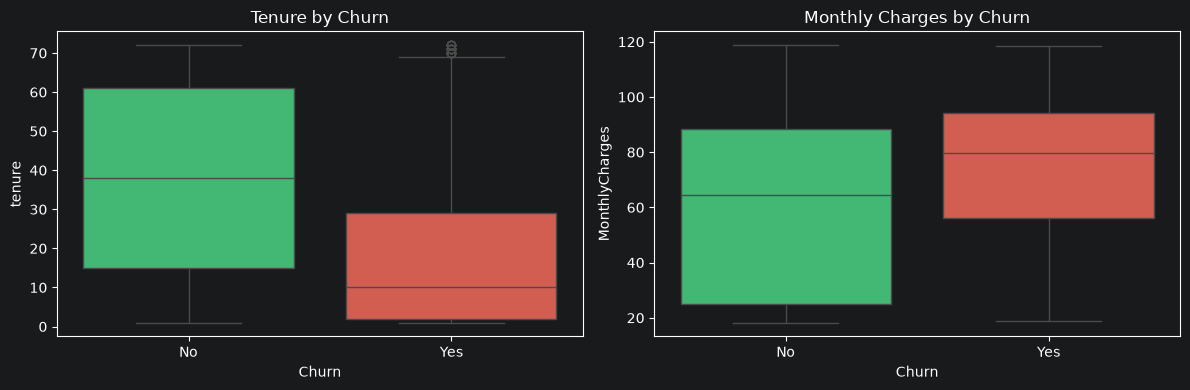

In [7]:
# Compare tenure and MonthlyCharges distributions by churn status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Tenure by Churn')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.show()

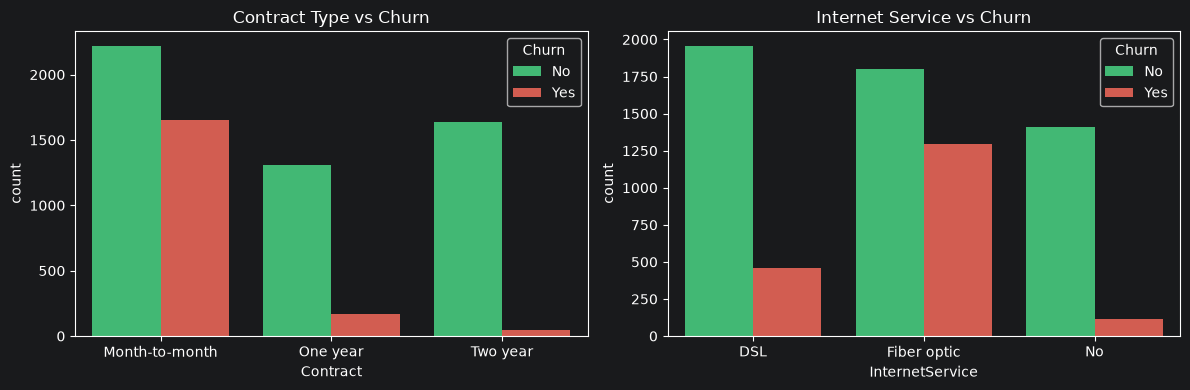

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Contract Type vs Churn')

sns.countplot(x='InternetService', hue='Churn', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Internet Service vs Churn')

plt.tight_layout()
plt.show()

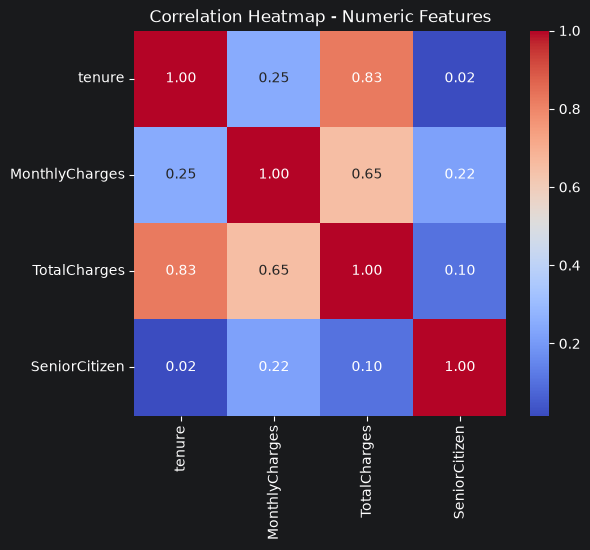

In [9]:
# Correlation heatmap for numeric features
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
plt.figure(figsize=(6,5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Numeric Features')
plt.show()

In [10]:
# Drop customerID (not useful for modeling)
df_model = df.drop('customerID', axis=1)

# Check which columns are categorical (object/str type)
categorical_cols = df_model.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", categorical_cols)
print("Count:", len(categorical_cols))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Count: 16


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21744\374126922.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_model.select_dtypes(include='object').columns.tolist()


In [11]:
from sklearn.preprocessing import LabelEncoder

# Separate target variable
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# Identify binary columns (excluding Churn, already encoded)
binary_cols = [col for col in categorical_cols if col != 'Churn' and df_model[col].nunique() == 2]
multi_cols = [col for col in categorical_cols if col != 'Churn' and df_model[col].nunique() > 2]

print("Binary columns:", binary_cols)
print("Multi-category columns:", multi_cols)

Binary columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
Multi-category columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']


In [12]:
# Label encode binary columns
le = LabelEncoder()
for col in binary_cols:
    df_model[col] = le.fit_transform(df_model[col])

# One-hot encode multi-category columns
df_model = pd.get_dummies(df_model, columns=multi_cols, drop_first=True)

print("Final shape:", df_model.shape)
df_model.head()

Final shape: (7032, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


In [13]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

# Train-test split (80-20, stratified to preserve churn ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nChurn ratio in train:", y_train.mean().round(3))
print("Churn ratio in test:", y_test.mean().round(3))

Training set: (5625, 30)
Test set: (1407, 30)

Churn ratio in train: 0.266
Churn ratio in test: 0.266


In [15]:
from sklearn.preprocessing import StandardScaler

numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print(X_train[numeric_features].describe())

             tenure  MonthlyCharges  TotalCharges
count  5.625000e+03    5.625000e+03  5.625000e+03
mean   3.157968e-17    2.147418e-17  6.315935e-18
std    1.000089e+00    1.000089e+00  1.000089e+00
min   -1.286145e+00   -1.547843e+00 -1.003365e+00
25%   -9.601500e-01   -9.698847e-01 -8.301191e-01
50%   -1.451620e-01    1.860324e-01 -3.918414e-01
75%    9.550717e-01    8.320837e-01  6.591681e-01
max    1.607062e+00    1.782062e+00  2.805224e+00


In [16]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_balanced.value_counts().to_dict())

Before SMOTE: {0: 4130, 1: 1495}
After SMOTE: {0: 4130, 1: 4130}


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Train Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000)
log_model.fit(X_train_balanced, y_train_balanced)

# Predict on test set
y_pred = log_model.predict(X_test)
y_pred_proba = log_model.predict_proba(X_test)[:, 1]

# Evaluate
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_pred_proba), 3))

              precision    recall  f1-score   support

           0       0.87      0.74      0.80      1033
           1       0.50      0.70      0.58       374

    accuracy                           0.73      1407
   macro avg       0.68      0.72      0.69      1407
weighted avg       0.77      0.73      0.74      1407

ROC-AUC Score: 0.815


In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_balanced, y_train_balanced)

y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_pred_proba_rf), 3))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83      1033
           1       0.54      0.65      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.73      0.71      1407
weighted avg       0.78      0.76      0.77      1407

ROC-AUC Score: 0.814


In [23]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_balanced, y_train_balanced)

y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_pred_proba_xgb), 3))

              precision    recall  f1-score   support

           0       0.86      0.79      0.82      1033
           1       0.52      0.64      0.58       374

    accuracy                           0.75      1407
   macro avg       0.69      0.71      0.70      1407
weighted avg       0.77      0.75      0.76      1407

ROC-AUC Score: 0.806


D:\PycharmProjects\SummerProject\Telco Customer Churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


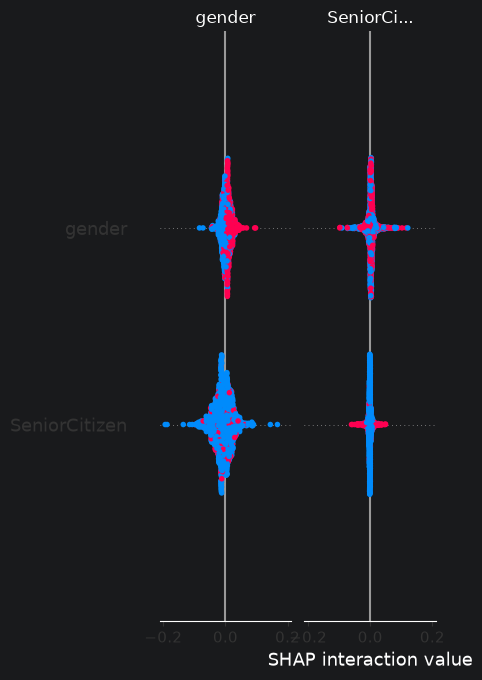

In [24]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values might be a list [class_0, class_1] or 2D array
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values

shap.summary_plot(shap_values_plot, X_test, plot_type='bar')

In [25]:
print("shap_values type:", type(shap_values))
if isinstance(shap_values, list):
    print("List length:", len(shap_values))
    print("Shape of each:", shap_values[0].shape, shap_values[1].shape)
else:
    print("Shape:", shap_values.shape)
print("X_test shape:", X_test.shape)

shap_values type: <class 'numpy.ndarray'>
Shape: (1407, 30, 2)
X_test shape: (1407, 30)


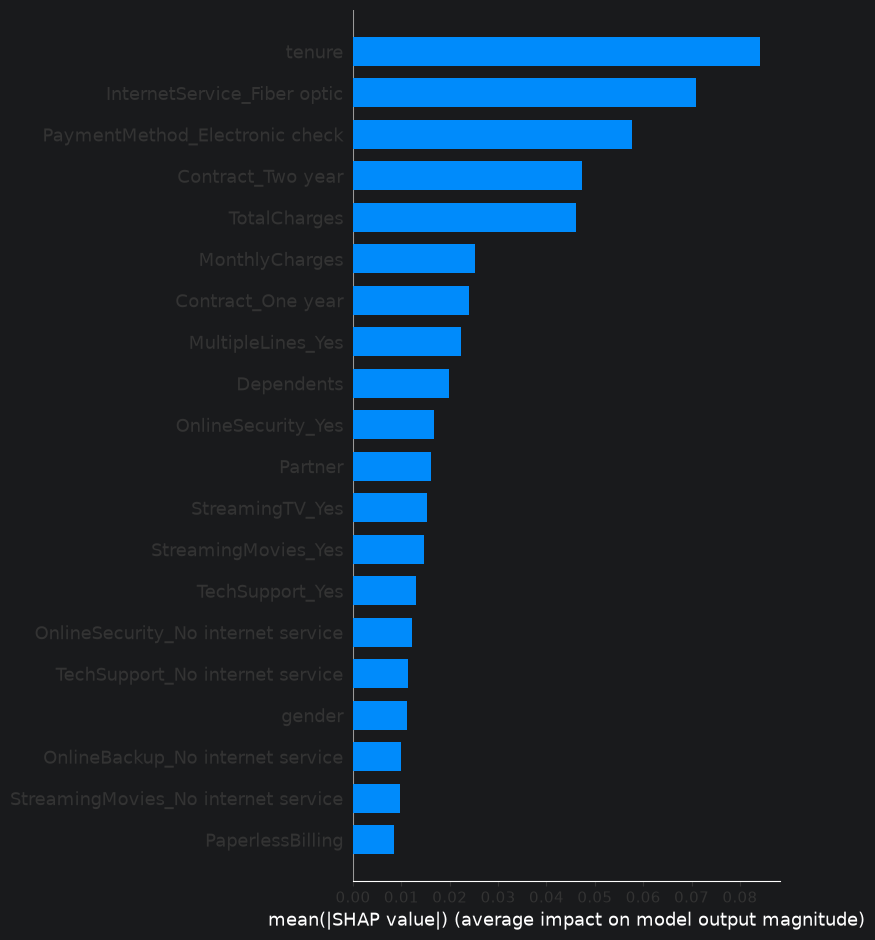

In [26]:
# Select SHAP values for the churn class (class 1)
shap_values_churn = shap_values[:, :, 1]

shap.summary_plot(shap_values_churn, X_test, plot_type='bar')

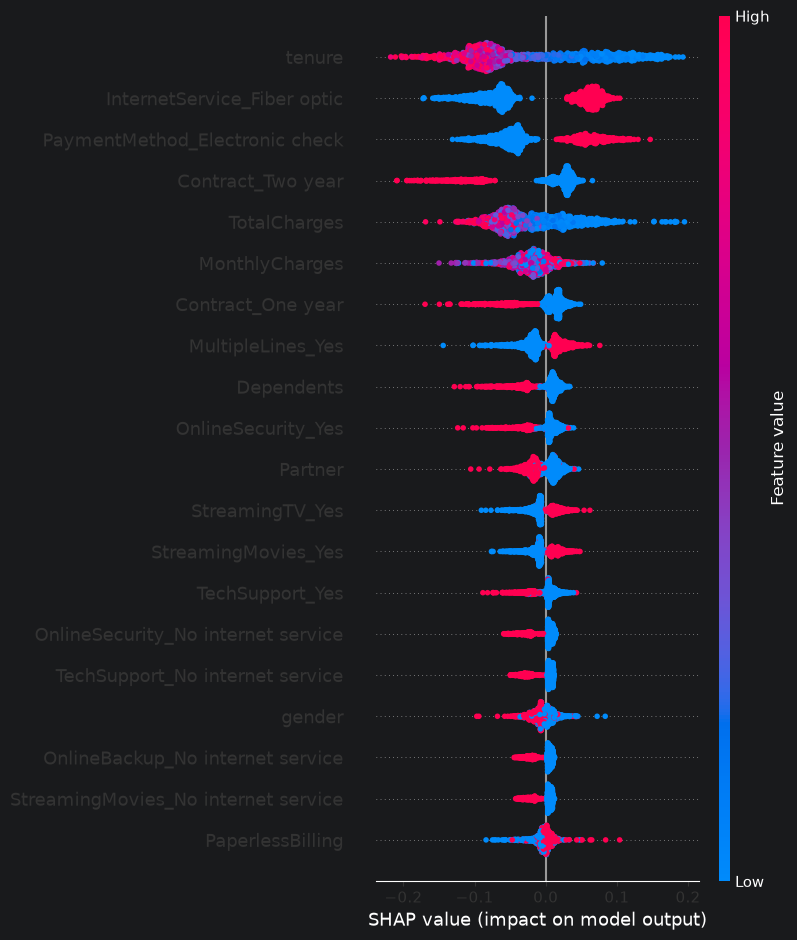

In [27]:
shap.summary_plot(shap_values_churn, X_test)

[[828 205]
 [130 244]]


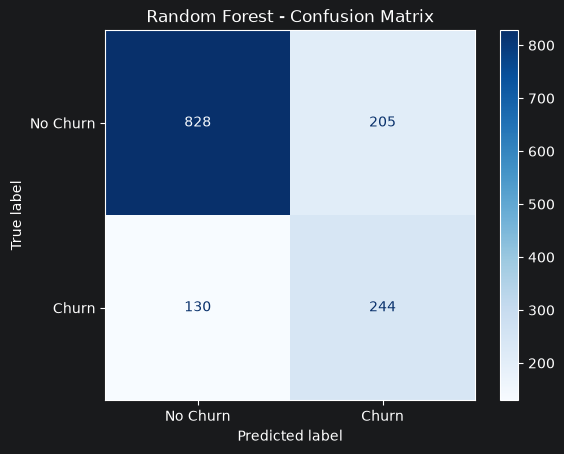

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [29]:
# Business assumptions (replace with real client values)
value_per_customer = 800    # revenue lost when one customer churns
offer_cost = 50             # cost of one retention offer
success_rate = 0.30         # share of targeted churners who accept the offer and stay

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()
total_churners = tp + fn

# Scenario 1: no model, all churners are lost
loss_without_model = total_churners * value_per_customer

# Scenario 2: target every customer the model flags as churn
customers_contacted = tp + fp
campaign_cost = customers_contacted * offer_cost
revenue_saved = tp * success_rate * value_per_customer
net_benefit = revenue_saved - campaign_cost

print("Loss without model:", loss_without_model)
print("Customers contacted:", customers_contacted)
print("Campaign cost:", campaign_cost)
print("Revenue saved:", round(revenue_saved))
print("Net benefit of using the model:", round(net_benefit))

Loss without model: 299200
Customers contacted: 449
Campaign cost: 22450
Revenue saved: 58560
Net benefit of using the model: 36110


In [30]:
# Try different probability thresholds and compute net benefit for each
thresholds = np.arange(0.2, 0.75, 0.05)
results = []

for t in thresholds:
    preds = (y_pred_proba_rf >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    cost = (tp + fp) * offer_cost
    saved = tp * success_rate * value_per_customer
    results.append((round(t, 2), tp, fp, fn, round(saved - cost)))

results_df = pd.DataFrame(results, columns=['threshold', 'TP', 'FP', 'FN', 'net_benefit'])
print(results_df)

    threshold   TP   FP   FN  net_benefit
0        0.20  340  470   34        41100
1        0.25  323  422   51        40270
2        0.30  308  372   66        39920
3        0.35  300  309   74        41550
4        0.40  281  279   93        39440
5        0.45  269  230  105        39610
6        0.50  249  208  125        36910
7        0.55  230  180  144        34700
8        0.60  203  142  171        31470
9        0.65  185  126  189        28850
10       0.70  160  105  214        25150


In [31]:
import joblib

# Save the trained model, scaler and feature column order
joblib.dump(rf_model, 'churn_rf_model.pkl')
joblib.dump(scaler, 'churn_scaler.pkl')
joblib.dump(X_train.columns.tolist(), 'feature_columns.pkl')

print("Saved files in project folder")

Saved files in project folder
